# Lista 2 (7 pkt.)

In [1]:
import string
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from pygments.formatters import img

## Zadanie 1. (1 pkt)

To zadanie należy wykonać ręcznie, bez używania komputera, korzystając z instrukcji z **one_time_pad.pdf**. Zaszyfruj wiadomość o treści: "NEW 15 HELICOPTERS.", za pomocą klucza: 68496 47757 10126 36660 25066. Do słów, które są w tabeli poniżej użyj odpowiednio ich kodów. Uwaga: w wiadomości jest liczba mnoga "helicopterS".

$\begin{array}{|c|c|c|c|c|c|c|c|c|c|}
\hline
CODE&A&E&I&N&O&T&&\\
0&1&2&3&4&5&6&&&\\
\hline
B&C&D&F&G&H&J&K&L&M\\
70&71&72&73&74&75&76&77&78&79\\
\hline
P&Q&R&S&U&V&W&X&Y&Z\\
80&81&82&83&84&85&86&87&88&89\\
\hline
FIG&.&:&,/'&(/)&+&-&=&REG/?&SPC\\
90&91&92&93&94&95&96&97&98&99\\
\hline
\end{array}$

$\begin{array}{|cc|cc|cc|cc|}
\hline
000&ABORT&253&DECODE&505&MILITARY&758&STREET\\
\hline
019&ACCEPT&262&DELAY&514&MONEY&767&SUBWAY\\
\hline
028&ACCESS&271&DIFFICULT&523&MONTH&776&SUCCESS\\
\hline
037&ADDRESS&280&DOCUMENT&532&MORNING&785&SUPPLY\\
\hline
046&AFFIRMATIVE&299&ENCODE&541&MORSE&794&SUPPORT\\
\hline
055&AGENT&307&EVENING&550&NEGATIVE&802&TELEPHONE\\
\hline
064&AIRPLANE&316&EXECUTE&569&NIGHT&811&TODAY\\
\hline
073&AIRPORT&325&FACTORY&578&OBSERVATION&820&TOMORROW\\
\hline
082&ANSWER&334&FAILED&587&PASSPORT&839&TRAIN\\
\hline
091&AUTHORITY&343&FERRY&596&PERSON&848&TRANSFER\\
\hline
109&BETWEEN&352&FLIGHT&604&PHOTOGRAPH&857&TRANSMIT\\
\hline
118&BORDER&361&FREQUENCY&613&POSITIVE&866&TRAVEL\\
\hline
127&BUILDING&370&HARBOUR&622&POSSIBLE&875&TRUCK\\
\hline
136&CANCEL&389&HELICOPTER&631&POWER&884&UNABLE TO\\
\hline
145&CHANGE&398&HIGHWAY&640&PRIORITY&893&URGENT\\
\hline
154&CIVILIAN&406&IDENTITY&659&PROBLEM&901&VERIFY\\
\hline
163&COMPROMISE&415&IMMEDIATE&668&QUESTION&910&WEEK\\
\hline
172&COMPUTER&424&IMPOSSIBLE&677&RADIO&929&WITHIN\\
\hline
181&CONFIRM&433&INFORMATION&686&RECEIVE&938&YESTERDAY\\
\hline
190&CONTACT&442&INSTRUCTIONS&695&RENDEZVOUS&&\\
\hline
208&COORDINATE&451&LOCATE&703&REPEAT&&\\
\hline
217&COUNTRY&460&LOCATION&712&RESERVATION&&\\
\hline
226&COVERT&479&MAIL&721&ROUTINE&\\
\hline
235&CURRENT&488&MEETING&730&SATELLITE&\\
\hline
244&DANGER&497&MESSAGE&749&SHIP&\\
\hline
\end{array}$

Najpierw znaki tesktu szyfrowanego na liczby (Plaincode):


*N E W 1 5 HELICPOTER S .*

*4 2 86 90 111 555 0389 83 91*

Następnie szyfr one time pad:

Plaincode  : KEYID 42869 01115 55038 98391

OTP Key(-) : 68496 47757 10126 36660 25066

*---------------------------------------------------*

Ciphertext : 68496 05112 91099 29478 73335


## Zadanie 2 (1 pkt)

To zadanie również jest do zrobienia ręcznie. Używając klucza 11454 03055 15565 17466 26950 54906 odkoduj wiadomość 11454 00572 94578 25863 84286 24376. Wykorzystaj instrukcje z one_time_pad.pdf oraz tablicę kodów z Zadania 1.

Ciphertext : 11454 00572 94578 25863 84286 24376

OTP Key(+) : 11454 03055 15565 17466 26950 54906

*----------------------------------------------------------*

Plaincode : KEYID 03527 09033 32229 00136 78272

Rozwiązujemy na podstawie tabeli kodów:

*0352 70 90 333 222 90 0136 78 2 72*

*Flight B 3 2 Cancel L E D*

## Zadanie 3. (1 pkt)

Wczytaj obrazki 'miki.png' oraz 'quest.png'.

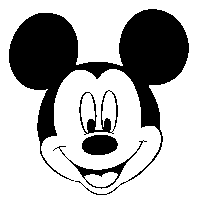

In [2]:
img1 = Image.open('miki.png').convert('L')
img1

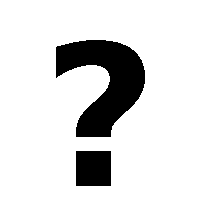

In [3]:
img2 = Image.open('quest.png').convert('L')
img2

Napisz funkcję **add_pic(img1, img2)**, która przyjmuje dwa obrazki i je dodaje piksel po pikselu za pomocą XOR, czyli **biały+biały=czarny, biały+czarny=biały, czarny+czarny=czarny**. Warto wykorzystać to, że **np.array(img)** zwraca tablicę, z wartościami 255 dla białych pikseli i 0 dla czarnych, aby zamienić tablicę z powrotem na obraz należy użyc **Image.fromarray()** przy czym tablica musi być typu **np.uint8** czyli tworząc tablicę podajemy typ: **np.array([1,2,3,4], dtype=np.uint8)**. Funkcja ma zwracać obrazek.

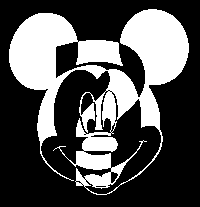

In [4]:
def add_pic(img1, img2):
    a = np.array(img1, dtype=np.uint8)
    b = np.array(img2, dtype=np.uint8)
    return Image.fromarray(np.bitwise_xor(a, b)).convert('L')

add_pic(img1, img2)

Wygeneruj (pseudo)losowy klucz, czyli obrazek z losowymi białymi i czarnymi pikselami, użyj **np.random**. Następnie zaszyfruj tym kluczem, za pomocą **add_pic**, oba obrazki **img1** i **img2**. Zauważ, że oba obrazki wyglądają na dobrze zaszyfrowane, zobacz jednak co się wydarzy kiedy dodasz do siebie te zaszyfrowane obrazki.

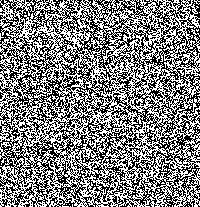

In [5]:
def random_pic(width, height):
    arr = np.random.randint(0, 2, (height, width), dtype=np.uint8) * 255
    return Image.fromarray(arr).convert('L')

klucz = random_pic(img1.width, img1.height)
klucz

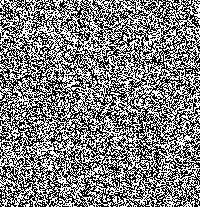

In [6]:
szyfrogram1 = add_pic(img1, klucz)
szyfrogram1

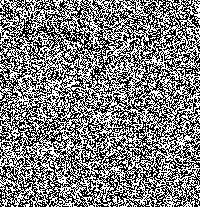

In [7]:
szyfrogram2 = add_pic(img2, klucz)
szyfrogram2

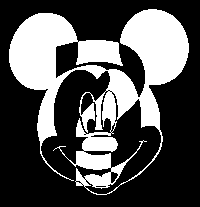

In [8]:
add_pic(szyfrogram1, szyfrogram2)

Wynika to z właściwości XOR:

$[
(A \oplus K) \oplus (B \oplus K) = A \oplus B
\$

Klucz K znosi się, ponieważ K XOR K = 0. W efekcie oba zaszyfrowane obrazy po operacji XOR ujawniają XOR oryginalnych obrazów.

## Zadanie 4 (2 pkt.)

Zmienne ***msg1_enc*** oraz ***msg2_enc*** zawierają dwie zaszyfrowane wiadomości, w języku angielskim.

In [9]:
msg1_enc = '\x1e\x17\x0c\x12\x1b\x08\x0cf\x0e\x11x\x1a\x1c\x12o\x06\x18\x1f\x17\x03\x10\x01fkh\x1f\x08'
msg2_enc = '\x0b\ni\x07\x1c\x02k\x1f\x16e\x01\x0b\x07\x03\n\x15\x15\x0c\x1el\x07\x03\x03\x16\x01\x01\x02'

Wiadomo, że zostały zaszyfrowane tym samym kluczem, możemy to wykorzystać do odszyfrowania ich. W tym zadaniu konwencja zamiany liter na liczby i ich dodawania jest inna, niż w poprzednich. Znaki zamieniamy na liczby kodujące te znaki w **Unicode**, czyli za pomocą **ord()**, następnie dodajemy je do siebie za pomocą XOR na poziomie bitów, czyli za pomocą **^**. Napisz funkcję **add_str(msg1, msg2)**, które przyjmuje dwa teksty i zwraca tekst będący sumą tych tekstów zgodnie z powyższą konwencją.

In [11]:
def add_str(msg1, msg2):
    wynik = ""
    for a, b in zip(msg1, msg2):
        wynik += chr(ord(a) ^ ord(b))
    return wynik

suma = add_str(msg1_enc, msg2_enc)
suma

'\x15\x1de\x15\x07\ngy\x18ty\x11\x1b\x11e\x13\r\x13\to\x17\x02e}i\x1e\n'

Zauważmy, że jeżeli dwie wiadomości są zaszyfrowane tym samym kluczem to dodanie ich do siebie sprawia, że dostaniemy sumę wiadomości bez klucza. Poza tym zauważmy, że jeżeli znamy jakieś słowo występujące w którejś z wiadomości i je dodamy do sumy tych wiadomości w odpowiednim miejscu to w wyniku dostaniemy poprawne słowo z drugiej wiadomości. Zatem metoda łamania tych wiadomości jest następująca, zgadujemy jakie słowo może być w którejś z wiadomości, dodajemy je w różnych miejscach sumy wiadomości i patrzymy czy powstaje coś co może być fragmentem poprawnego tekstu, następnie na podstawie tego fragmentu zgadujemy większą pozostałą część słowa i teraz to słowo używamy do odczytania kolejnego fragmentu z pierwszej wiadomości.

Pierwsze słowo wybieramy z pośród najpopularniejszych słów w danym języku.

Najpopularniejsze angielskie słowa:
1. THE
2. BE
3. TO
4. OF
5. AND

Uwaga 1: Słowa zapisane są drukowanymi literami.

Uwaga 2: Słowa oddzialane są spacjami, zatem biorąc np. słowo THE należy sprawdzać ciąg znaków "&nbsp; THE &nbsp;", ze spacjami na początku i końcu, dzięki temu odszyfrujemy więcej znaków.

In [12]:
def szukaj_slowa(suma, slowo):
    for i in range(len(suma) - len(slowo) + 1):
        fragment = suma[i:i + len(slowo)]
        print(i, add_str(fragment, slowo))

In [14]:
szukaj_slowa(suma, " THE ")

0 5I-P'
1 =1]B*
2 EAOOG
3 5SB"Y
4 '^/<8
5 *31]T
6 G-P1Y
7 YL<<1
8 8 1T;
9 T-Y^1
10 YESTE
11 1OY 3
12 ;E-V-
13 11[H3
14 EGEV)
15 3Y[LO
16 -GA*7
17 3]'R"
18 );_GE
19 OCJ ]
20 7V-8I
21 "15,>
22 E)![*


2  EAOOG

10 YESTE

In [15]:
szukaj_slowa(suma, " BE ")

0 5_ 5
1 ='P'
2 EWB*
3 5EOG
4 'H"Y
5 *%<8
6 G;]T
7 YZ1Y
8 86<1
9 T;T;
10 YS^1
11 1YTE
12 ;S 3
13 1'V-
14 EQH3
15 3OV)
16 -QLO
17 3K*7
18 )-R"
19 OUGE
20 7@ ]
21 "'8I
22 E?,>
23 ]+[*


19 OUGE


In [16]:
szukaj_slowa(suma, " TO ")

0 5I*5
1 =1Z'
2 EAH*
3 5SEG
4 '^(Y
5 *368
6 G-WT
7 YL;Y
8 8 61
9 T-^;
10 YET1
11 1O^E
12 ;E*3
13 11\-
14 EGB3
15 3Y\)
16 -GFO
17 3] 7
18 );X"
19 OCME
20 7V*]
21 "12I
22 E)&>
23 ]=Q*


19 OCME

In [17]:
szukaj_slowa(suma, " OF ")

0 5R#5
1 =*S'
2 EZA*
3 5HLG
4 'E!Y
5 *(?8
6 G6^T
7 YW2Y
8 8;?1
9 T6W;
10 Y^]1
11 1TWE
12 ;^#3
13 1*U-
14 E\K3
15 3BU)
16 -\OO
17 3F)7
18 ) Q"
19 OXDE
20 7M#]
21 "*;I
22 E2/>
23 ]&X*


19 OXDE

In [18]:
szukaj_slowa(suma, " AND ")

0 5\+Q'
1 =$[C*
2 ETING
3 5FD#Y
4 'K)=8
5 *&7\T
6 G8V0Y
7 YY:=1
8 857U;
9 T8__1
10 YPUUE
11 1Z_!3
12 ;P+W-
13 1$]I3
14 ERCW)
15 3L]MO
16 -RG+7
17 3H!S"
18 ).YFE
19 OVL!]
20 7C+9I
21 "$3->
22 E<'Z*


2  ETING

10 YPUUE

**Jedyne które mają sens to:**

2  ETING -> MEETING, GREETING, SLEEPING

10 YESTE -> YESTERDAY

In [24]:
def znajdz_wiecej(suma, i , slowo):
    return add_str(suma[i:i + len(slowo)], slowo)

In [25]:
znajdz_wiecej(suma, 9, " YESTERDAY ")

'T THE AIRPO'

In [27]:
znajdz_wiecej(suma, 0, "MEETING ")

'XX AND Y'

In [30]:
znajdz_wiecej(suma, 0, "GREETING ")

'RO PSC)>8'

In [31]:
znajdz_wiecej(suma, 0, "SLEEPING ")

'FQ PWC)>8'

Dalej możemy wnioskować: T THE AIRPORT -> at the airport

MEETING rozpoczyna wiadomość i są to znaki od 0 do 7, więc prawdopodobnie następnie może być nasze AT THE AIRPORT, czyli MEETING AT THE AIRPORT (wiadomość 1)

In [32]:
znajdz_wiecej(suma, 0, "MEETING AT THE AIRPORT ")

'XX AND YY YESTERDAY EVE'

wiadomość 2 - **xx and yy yesterdat eve**ning?

In [33]:
znajdz_wiecej(suma, 0, "XX AND YY YESTERDAY EVENING ")

'MEETING AT THE AIRPORT 3 PM'

In [36]:
msg_1 = znajdz_wiecej(suma, 0, "XX AND YY YESTERDAY EVENING")
msg_2 = znajdz_wiecej(suma, 0, msg_1)

print(msg_1)
print(msg_2)

MEETING AT THE AIRPORT 3 PM
XX AND YY YESTERDAY EVENING


In [37]:
print(len(msg_1) == len(msg1_enc))

True


In [38]:
print(len(msg_2) == len(msg2_enc))

True


**To już całe nasze wiadomości**

Żeby znaleźć klucz wystarczy teraz dodać zaszyfrowaną wiadomość do niezaszyfrowanej.

In [40]:
key = add_str(msg_1, msg1_enc)
print(key)

SRIFRFKFOEXNTWOGQMGLBUFXHOE


## Zadanie 5 (2 pkt.)

W poprzednim zadaniu korzystaliśmu z faktu, że obie wiadomości były zaszyfrowane przy użyciu tego samego klucza. Jednka w praktyce nie wiemy, które i czy w ogóle, wiadomosci były zaszyfrowane przy użyciu tego samego klucza. Możemy to wykryć dokonując analizy statystycznej. Załóżmy, że dodajemy do siebie dwie wiadomości zaszyfrowane tymi samymi kluczami. Wtedy miejsca w których dostaniemy 0 (w konwencji użytej w tym zadaniu znak odpowiadający 0 w Unicode, czyli chr(0)) są miejscami w których w obu wiadomościach była ta sama litera. Jeżeli natomiast dodajemy wiadomości o różnych kluczach będziemy dostawać 0 w losowych miejscach. Zatem w pierwszym przypadku otrzymamy więcej 0.

Zatem należy wczytać wszystkie wiadomości msg1.txt, msg2.txt itd. a następnie dodać je do siebie parami, każda z każdą i policzyć odsetek 0 (tzn. znaków chr(0)) w otrzymanych sumach. Para wiadomości o wyższym niż inne odsetku będzie tą zaszyfrowaną przy u życiu tego samego klucza. Aby łatwiej zauważyć taką parę warto zilustrować sobie wyniki (odsetki 0) za pomocą **plt.imshow(X ,norm=LogNorm())** i użyć skali logarytmicznej, gdzie **X** to tablica 10 na 10 zawierająca odsetki 0 dla każdej pary wiadomości.

In [43]:
wiadomosci = []

for i in range(0, 10):
    with open(f'msg{i}.txt', encoding='utf-8') as f:
        wiadomosci.append(f.read())

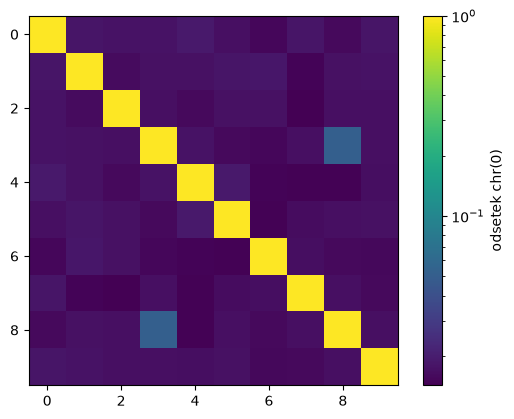

In [48]:
X = np.zeros((10, 10))

for i in range(10):
    for j in range(10):
        suma = add_str(wiadomosci[i], wiadomosci[j])
        X[i, j] = suma.count(chr(0)) / len(suma)

plt.imshow(X, norm=LogNorm())
plt.colorbar(label='odsetek chr(0)')
plt.show()

Pliki msg3.txt i msg8.txt są prawdopodobnie zaszyfrowane tym samym kluczem.